In [319]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [320]:
df = pd.read_csv("../data/marketing_campaign.csv", sep='\t')
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [321]:
df.shape

(2240, 29)

In [322]:
columns=df.columns

In [323]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [324]:
pd.set_option('display.max_columns', None)
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,44.021875,2.325000,4.084821,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,52.167439,1.932238,2.778714,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [325]:
df.isna().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [326]:
df['Income'].describe()

count      2216.000000
mean      52247.251354
std       25173.076661
min        1730.000000
25%       35303.000000
50%       51381.500000
75%       68522.000000
max      666666.000000
Name: Income, dtype: float64

Text(0.5, 1.0, 'Income distribution')

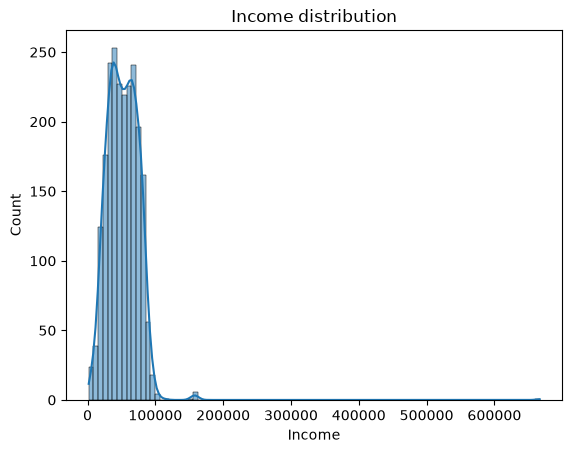

In [327]:
sns.histplot(df['Income'], kde=True)
plt.title("Income distribution")

<Axes: xlabel='Income'>

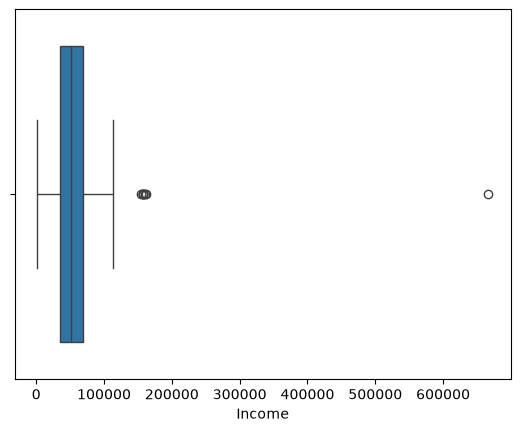

In [328]:
sns.boxplot(x=df["Income"])

<Axes: xlabel='Year_Birth', ylabel='Count'>

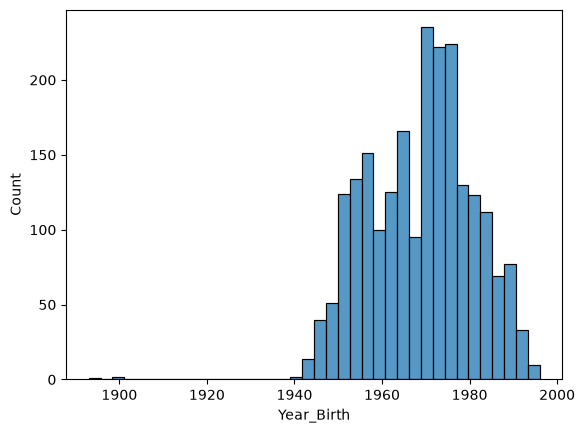

In [329]:
sns.histplot(df["Year_Birth"])

<Axes: xlabel='Recency', ylabel='Count'>

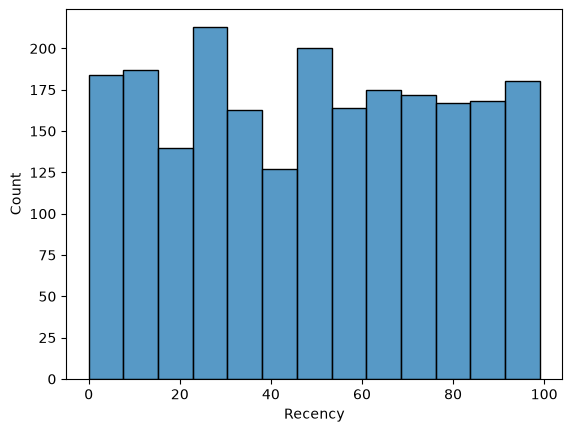

In [330]:
sns.histplot(df["Recency"])

<Axes: xlabel='Recency'>

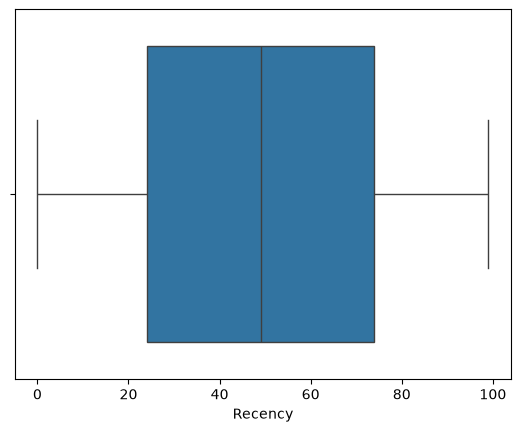

In [331]:
sns.boxplot(x=df["Recency"])

In [332]:
mnt_cols = [col for col in df.columns if col.startswith('Mnt')]
df['Total_Spending'] = df[mnt_cols].sum(axis=1)

<Axes: xlabel='Total_Spending', ylabel='Count'>

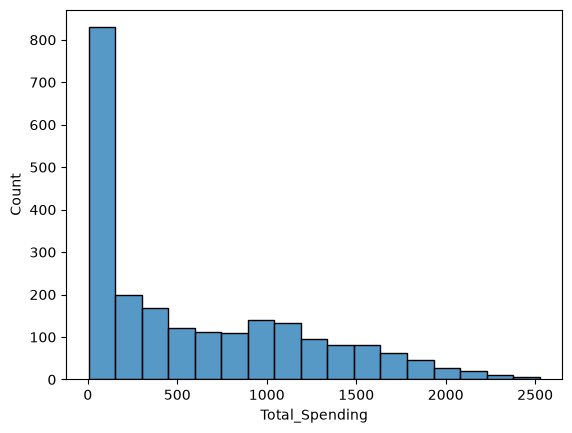

In [333]:
sns.histplot(df["Total_Spending"])


In [334]:
categorical_cols=df.select_dtypes(include='object').columns
categorical_cols
cat_cols = ['Education', 'Marital_Status']

In [335]:
numerical_cols=df.select_dtypes(include='number').columns
numerical_cols

Index(['ID', 'Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency',
       'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
       'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases',
       'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
       'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5',
       'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact',
       'Z_Revenue', 'Response', 'Total_Spending'],
      dtype='str')

<Axes: xlabel='Education', ylabel='count'>

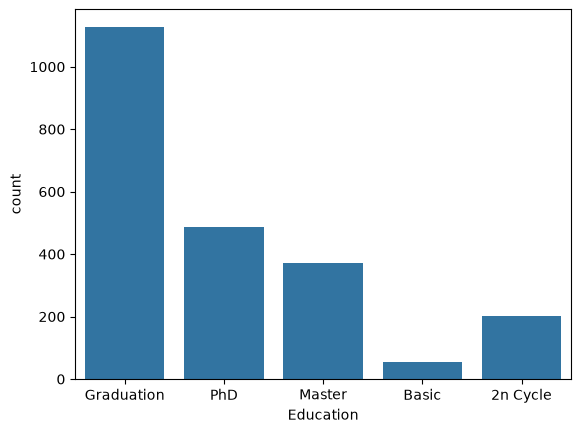

In [336]:
sns.countplot(data=df, x="Education")

([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'Single'),
  Text(1, 0, 'Together'),
  Text(2, 0, 'Married'),
  Text(3, 0, 'Divorced'),
  Text(4, 0, 'Widow'),
  Text(5, 0, 'Alone'),
  Text(6, 0, 'Absurd'),
  Text(7, 0, 'YOLO')])

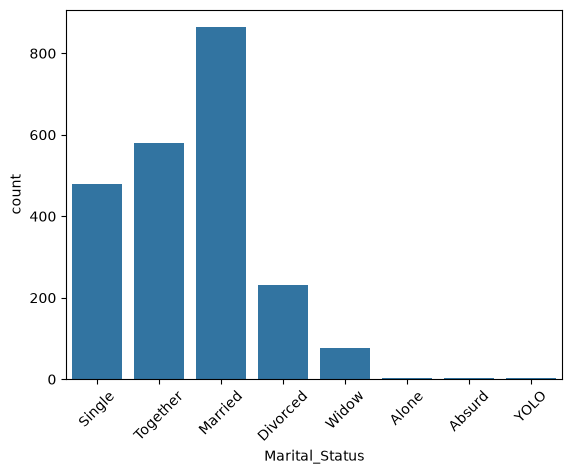

In [337]:
sns.countplot(data=df, x="Marital_Status")
plt.xticks(rotation=45)

In [338]:
df['Marital_Status'].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [339]:
df['Marital_Status'] = df['Marital_Status'].replace({
    'Together': 'Married'
})
df['Marital_Status'] = df['Marital_Status'].replace({
    'Alone': 'Single'
})

In [340]:
df['Marital_Status'].value_counts()

Marital_Status
Married     1444
Single       483
Divorced     232
Widow         77
Absurd         2
YOLO           2
Name: count, dtype: int64

In [341]:
df["Response"].value_counts()

Response
0    1906
1     334
Name: count, dtype: int64

<Axes: xlabel='Income', ylabel='Total_Spending'>

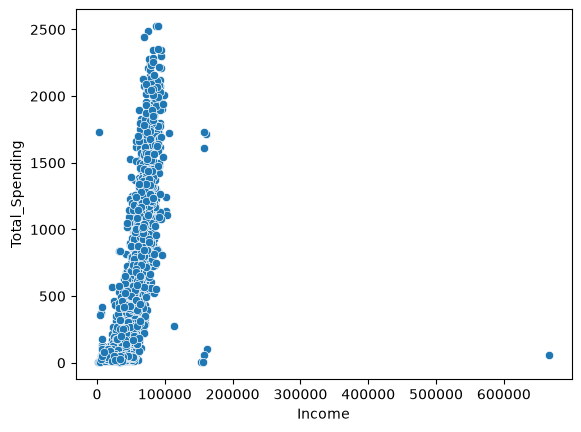

In [342]:
sns.scatterplot(data=df, x="Income", y="Total_Spending")

<Axes: xlabel='Age', ylabel='Total_Spending'>

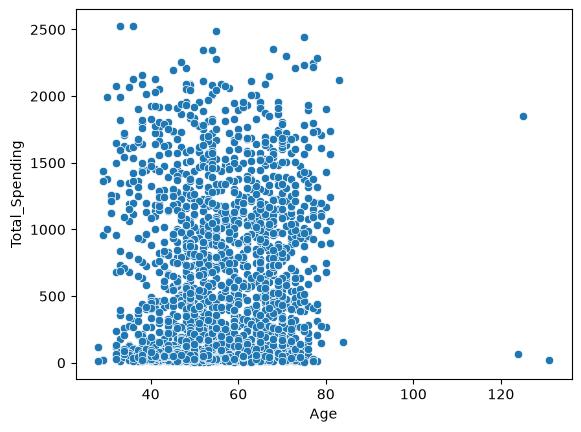

In [343]:
df['Age'] = 2024 - df['Year_Birth']
sns.scatterplot(data=df, x='Age', y='Total_Spending')

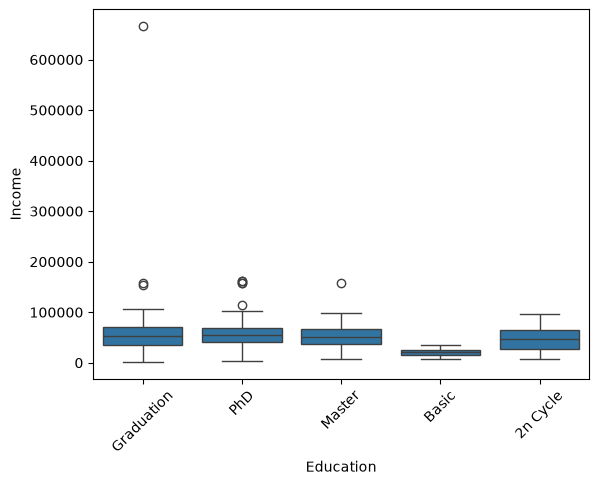

In [344]:
sns.boxplot(data=df, x='Education', y='Income')
plt.xticks(rotation=45)
plt.show()

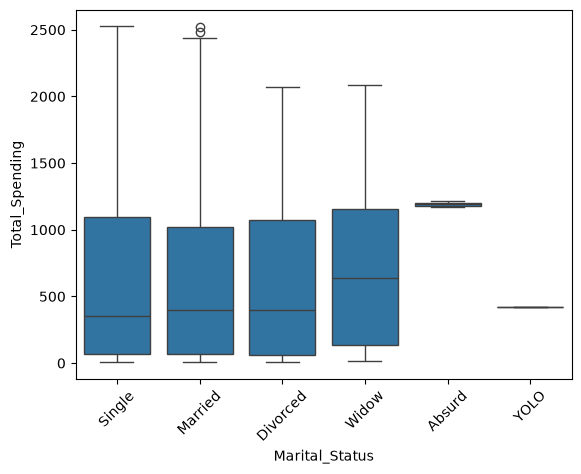

In [345]:
sns.boxplot(data=df, x='Marital_Status', y='Total_Spending')
plt.xticks(rotation=45)
plt.show()

In [346]:
df["Marital_Status"].value_counts()

Marital_Status
Married     1444
Single       483
Divorced     232
Widow         77
Absurd         2
YOLO           2
Name: count, dtype: int64

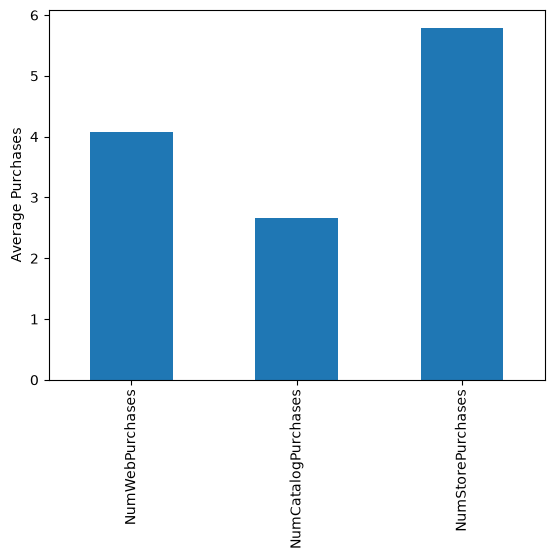

In [347]:
purchase_channel_cols = [
    'NumWebPurchases',
    'NumCatalogPurchases',
    'NumStorePurchases'
]

df[purchase_channel_cols].mean().plot(kind='bar')
plt.ylabel('Average Purchases')
plt.show()

In [348]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response',
       'Total_Spending', 'Age'],
      dtype='str')

In [349]:
numerical_cols = [col for col in numerical_cols if not col[:3]=="Mnt"]
numerical_cols.append('Total_Spending')
numerical_cols

['ID',
 'Year_Birth',
 'Income',
 'Kidhome',
 'Teenhome',
 'Recency',
 'NumDealsPurchases',
 'NumWebPurchases',
 'NumCatalogPurchases',
 'NumStorePurchases',
 'NumWebVisitsMonth',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'AcceptedCmp1',
 'AcceptedCmp2',
 'Complain',
 'Z_CostContact',
 'Z_Revenue',
 'Response',
 'Total_Spending',
 'Total_Spending']

In [350]:
df=df.drop(columns=['Z_CostContact', 'Z_Revenue'])
numerical_cols = [col for col in numerical_cols if col not in ['Z_CostContact', 'Z_Revenue']]

<Axes: >

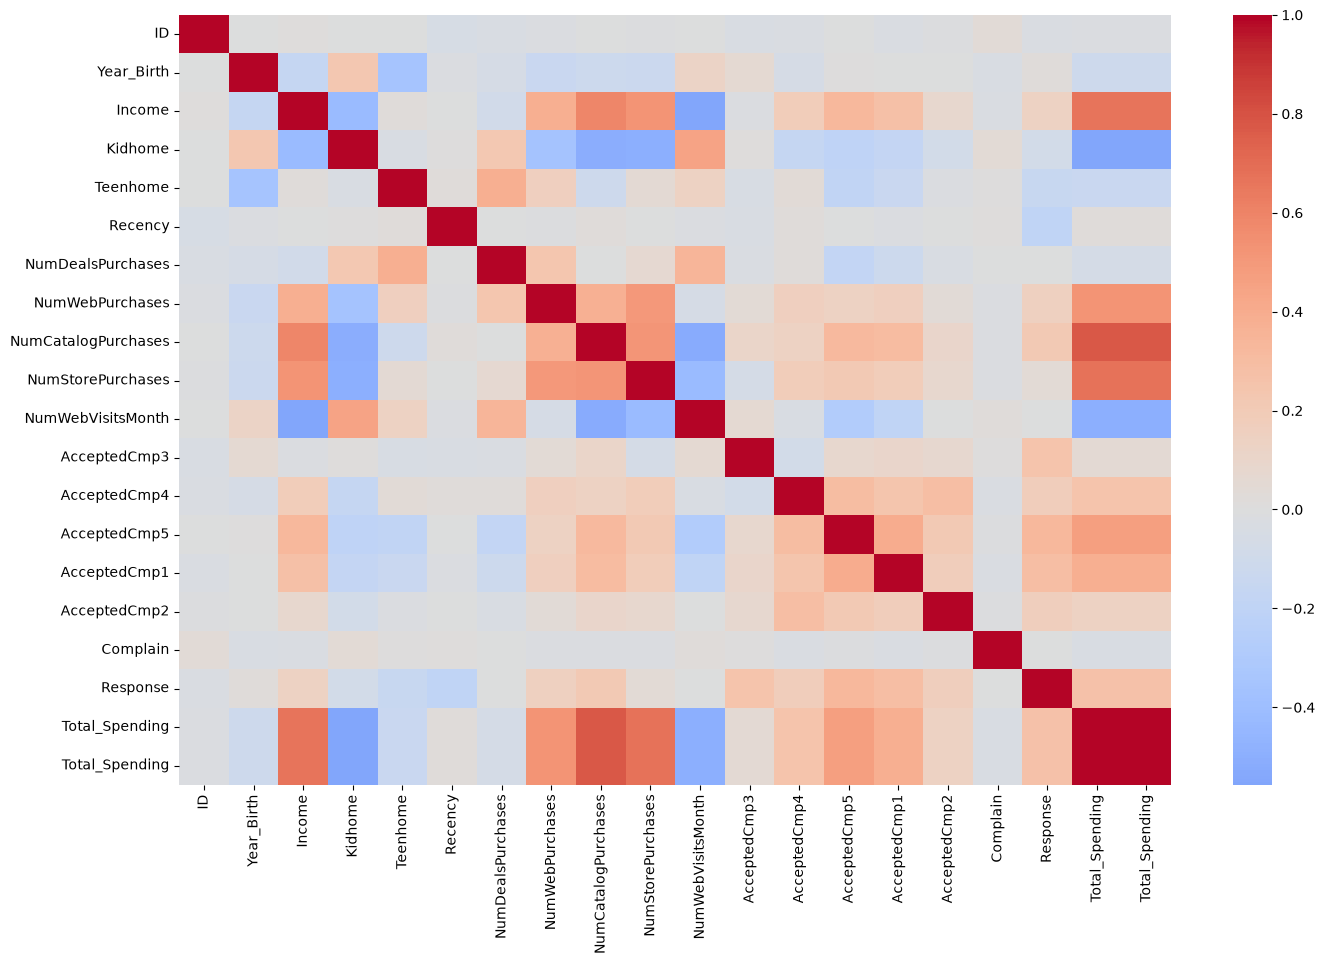

In [351]:
plt.figure(figsize=(16, 10))

sns.heatmap(df[numerical_cols].corr(),cmap='coolwarm',
    center=0)

In [352]:
df = df[df['Income'].isna() | (df['Income'] < 300000)].copy()
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Total_Spending,Age
count,2239.000000,2239.000000,2215.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000,2239.000000
mean,5590.444841,1968.802144,51969.861400,0.443948,0.506476,49.121036,304.067441,26.307727,167.016525,37.538633,27.074587,44.036177,2.324252,4.085306,2.662796,5.791425,5.316213,0.072800,0.074587,0.072800,0.064314,0.013399,0.009379,0.149174,606.041090,55.197856
std,3246.372471,11.985494,21526.320095,0.538390,0.544555,28.963662,336.614830,39.781468,225.743829,54.637617,41.286043,52.174700,1.932345,2.779240,2.923542,3.251149,2.427144,0.259867,0.262782,0.259867,0.245367,0.115001,0.096412,0.356339,602.274089,11.985494
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,28.000000
25%,2827.500000,1959.000000,35284.000000,0.000000,0.000000,24.000000,24.000000,1.000000,16.000000,3.000000,1.000000,9.000000,1.000000,2.000000,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,69.000000,47.000000
50%,5455.000000,1970.000000,51373.000000,0.000000,0.000000,49.000000,174.000000,8.000000,67.000000,12.000000,8.000000,24.000000,2.000000,4.000000,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,396.000000,54.000000
75%,8423.500000,1977.000000,68487.000000,1.000000,1.000000,74.000000,504.500000,33.000000,232.000000,50.000000,33.000000,56.000000,3.000000,6.000000,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1046.000000,65.000000
max,11191.000000,1996.000000,162397.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,362.000000,15.000000,27.000000,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2525.000000,131.000000


In [353]:
df=df[df['Year_Birth']>=1940].copy()
df['Year_Birth'].describe()

count    2236.000000
mean     1968.898032
std        11.703281
min      1940.000000
25%      1959.000000
50%      1970.000000
75%      1977.000000
max      1996.000000
Name: Year_Birth, dtype: float64

In [354]:
df = df[(df['Marital_Status'] != 'YOLO') & (df['Marital_Status'] != 'Absurd')].copy()
df['Marital_Status'].value_counts()

Marital_Status
Married     1442
Single       482
Divorced     231
Widow         77
Name: count, dtype: int64

In [355]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Response', 'Total_Spending', 'Age'],
      dtype='str')

In [356]:
purchase_channel_cols
df['Total_Purchases']=df[purchase_channel_cols].sum(axis=1)
df['Total_Purchases']

0       22
1        4
2       20
3        6
4       14
        ..
2235    16
2236    15
2237    18
2238    21
2239     8
Name: Total_Purchases, Length: 2232, dtype: int64

In [357]:
campaign_cols = ['AcceptedCmp1',                 
                 'AcceptedCmp2',
                 'AcceptedCmp3',
                 'AcceptedCmp4',
                 'AcceptedCmp5']
df['Total_Accepted_Campaigns']=df[campaign_cols].sum(axis=1)
df['Total_Accepted_Campaigns']

0       0
1       0
2       0
3       0
4       0
       ..
2235    0
2236    1
2237    1
2238    0
2239    0
Name: Total_Accepted_Campaigns, Length: 2232, dtype: int64

In [358]:
df[['Age', 'Total_Spending', 'Total_Purchases', 'Total_Accepted_Campaigns']].describe()

,Age,Total_Spending,Total_Purchases,Total_Accepted_Campaigns
count,2232.000000,2232.000000,2232.000000,2232.000000
mean,55.111111,605.624104,12.540771,0.297491
std,11.699288,602.123276,7.210614,0.678301
min,28.000000,5.000000,0.000000,0.000000
25%,47.000000,69.000000,6.000000,0.000000
50%,54.000000,396.000000,12.000000,0.000000
75%,65.000000,1044.250000,18.000000,0.000000
max,84.000000,2525.000000,32.000000,4.000000


<Axes: >

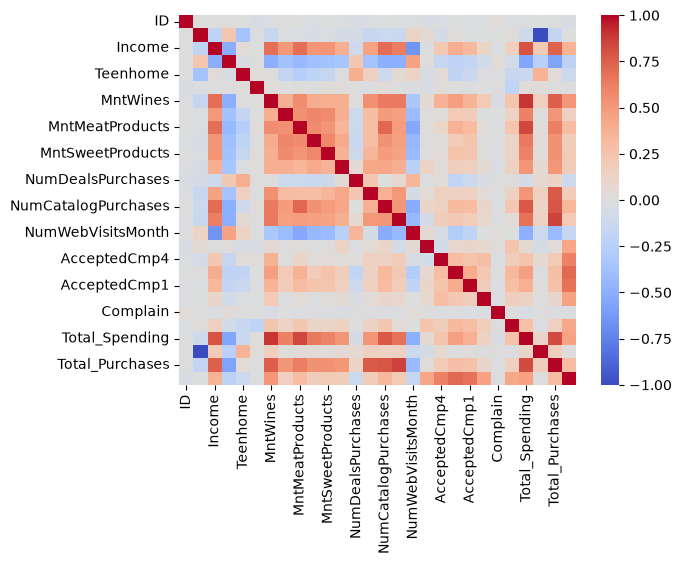

In [359]:
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    cmap='coolwarm',
    center=0,
)


In [360]:
drop_cols = [
    'ID',
    'Year_Birth',
    'AcceptedCmp1',
    'AcceptedCmp2',
    'AcceptedCmp3',
    'AcceptedCmp4',
    'AcceptedCmp5',
    'Dt_Customer',
    'Complain'
]

df=df.drop(columns=drop_cols)

In [361]:
df['Children'] = df['Kidhome'] + df['Teenhome']

In [362]:
df.columns

Index(['Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome',
       'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts',
       'MntFishProducts', 'MntSweetProducts', 'MntGoldProds',
       'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases',
       'NumStorePurchases', 'NumWebVisitsMonth', 'Response', 'Total_Spending',
       'Age', 'Total_Purchases', 'Total_Accepted_Campaigns', 'Children'],
      dtype='str')

In [363]:
features = [
    'Income',
    'Total_Spending',
    'Total_Purchases',
    'Children',
    'NumWebVisitsMonth',
    'NumDealsPurchases'
]
X = df[features].copy()

y_response = df['Response'].copy()
X.head()

,Income,Total_Spending,Total_Purchases,Children,NumWebVisitsMonth,NumDealsPurchases
0,58138.0,1617,22,0,7,3
1,46344.0,27,4,2,5,2
2,71613.0,776,20,0,4,1
3,26646.0,53,6,1,6,2
4,58293.0,422,14,1,5,5


In [364]:
X.info()

<class 'pandas.DataFrame'>
Index: 2232 entries, 0 to 2239
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Income             2208 non-null   float64
 1   Total_Spending     2232 non-null   int64  
 2   Total_Purchases    2232 non-null   int64  
 3   Children           2232 non-null   int64  
 4   NumWebVisitsMonth  2232 non-null   int64  
 5   NumDealsPurchases  2232 non-null   int64  
dtypes: float64(1), int64(5)
memory usage: 122.1 KB


In [365]:
# categorical_cols=['Education', 'Marital_Status']
# numerical_cols=X.select_dtypes(include='number').columns.tolist()
# print(numerical_cols)
# print(categorical_cols)

Preprocessing Pipelines

In [366]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

In [367]:
income_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Total_Spending: log transformation + scaling
spending_pipeline = Pipeline([
    ('log', FunctionTransformer(np.log1p)),
    ('scaler', StandardScaler())
])
other_features = [
    'Total_Purchases',
    'Children',
    'NumWebVisitsMonth',
    'NumDealsPurchases'
]

In [368]:
preprocessor = ColumnTransformer([
    ('income', income_pipeline, ['Income']),
    ('spending', spending_pipeline, ['Total_Spending']),
    ('other', StandardScaler(), other_features)
])

In [369]:
X_scaled = preprocessor.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)
X_scaled.head()

,Income,Total_Spending,Total_Purchases,Children,NumWebVisitsMonth,NumDealsPurchases
0,0.289534,1.203176,1.312142,-1.265157,0.692985,0.349860
1,-0.261178,-1.556566,-1.184737,1.393818,-0.131944,-0.167627
2,0.918740,0.704183,1.034711,-1.265157,-0.544409,-0.685114
3,-1.180963,-1.109769,-0.907306,0.064330,0.280520,-0.167627
4,0.296772,0.290523,0.202418,0.064330,-0.131944,1.384834


In [370]:
X_scaled.head()

,Income,Total_Spending,Total_Purchases,Children,NumWebVisitsMonth,NumDealsPurchases
0,0.289534,1.203176,1.312142,-1.265157,0.692985,0.349860
1,-0.261178,-1.556566,-1.184737,1.393818,-0.131944,-0.167627
2,0.918740,0.704183,1.034711,-1.265157,-0.544409,-0.685114
3,-1.180963,-1.109769,-0.907306,0.064330,0.280520,-0.167627
4,0.296772,0.290523,0.202418,0.064330,-0.131944,1.384834


In [371]:
X_scaled.isnull().sum()

Income               0
Total_Spending       0
Total_Purchases      0
Children             0
NumWebVisitsMonth    0
NumDealsPurchases    0
dtype: int64

In [372]:
X_scaled.describe().round(2)

,Income,Total_Spending,Total_Purchases,Children,NumWebVisitsMonth,NumDealsPurchases
count,2232.00,2232.00,2232.00,2232.00,2232.00,2232.00
mean,-0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.34,-2.60,-1.74,-1.27,-2.19,-1.20
25%,-0.77,-0.93,-0.91,-1.27,-0.96,-0.69
50%,-0.03,0.25,-0.08,0.06,0.28,-0.17
75%,0.76,0.91,0.76,0.06,0.69,0.35
max,5.16,1.51,2.70,2.72,6.06,6.56


In [373]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [374]:
results = []

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)
    db_score = davies_bouldin_score(X_scaled, labels)

    cluster_sizes = pd.Series(labels).value_counts().sort_index()

    results.append({
        'K': k,
        'Silhouette Score': silhouette,
        'Davies-Bouldin Score': db_score,
        'Cluster Sizes': cluster_sizes.tolist()
    })

results_df = pd.DataFrame(results)
results_df

,K,Silhouette Score,Davies-Bouldin Score,Cluster Sizes
0,2,0.393614,1.039644,"[1026, 1206]"
1,3,0.370955,1.095376,"[555, 737, 940]"
2,4,0.346782,1.128510,"[230, 502, 924, 576]"
3,5,0.306203,1.203877,"[560, 658, 498, 205, 311]"
4,6,0.297513,1.242863,"[194, 481, 307, 531, 396, 323]"


In [375]:
from sklearn.pipeline import Pipeline

clustering_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('clustering', KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

df['Cluster'] = clustering_pipeline.fit_predict(X)

In [376]:
df['Cluster'].value_counts().sort_index()

Cluster
0    555
1    737
2    940
Name: count, dtype: int64

In [377]:
cluster_summary = df.groupby('Cluster')[features].mean().round(2)
cluster_summary

,Income,Total_Spending,Total_Purchases,Children,NumWebVisitsMonth,NumDealsPurchases
Cluster,,,,,,
0,55199.55,694.26,16.31,1.34,6.44,4.62
1,73313.43,1207.80,18.73,0.32,2.97,1.22
2,33227.06,81.16,5.46,1.22,6.50,1.83


In [378]:
# Response rate will tell us whether customers in different clusters respond differently to marketing campaigns
response_summary = df.groupby('Cluster')['Response'].mean().mul(100).round(2)
response_summary

Cluster
0    13.87
1    23.47
2     8.72
Name: Response, dtype: float64

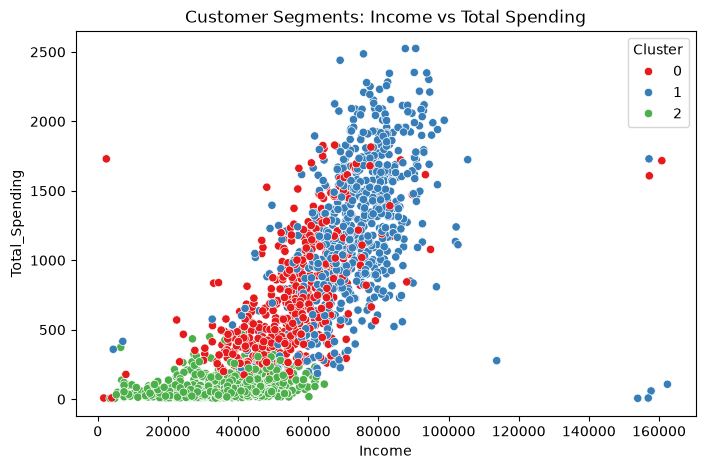

In [379]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Income',
    y='Total_Spending',
    hue='Cluster',
    palette='Set1',
    # alpha=0.7
)

plt.title('Customer Segments: Income vs Total Spending')
plt.show()

In [380]:
segment_names = {
    0: 'Moderate-value customers',
    1: 'High-value customers',
    2: 'Low-spending customers'
}

df['Segment'] = df['Cluster'].map(segment_names)

final_summary = df.groupby(['Cluster', 'Segment']).agg(
    Customers=('Cluster', 'size'),
    Income=('Income', 'mean'),
    Spending=('Total_Spending', 'mean'),
    Purchases=('Total_Purchases', 'mean'),
    Response_Rate=('Response', 'mean')
).round(2)

final_summary['Response_Rate'] *= 100

final_summary

,,Customers,Income,Spending,Purchases,Response_Rate
Cluster,Segment,,,,,
0,Moderate-value customers,555,55199.55,694.26,16.31,14.0
1,High-value customers,737,73313.43,1207.80,18.73,23.0
2,Low-spending customers,940,33227.06,81.16,5.46,9.0


In [382]:
import joblib

joblib.dump(clustering_pipeline, '../models/clustering_pipeline.pkl')

['../models/clustering_pipeline.pkl']